**公开阅读版：** 不包含微博数据集，也不保留运行输出。课堂数据由教师另行提供，放在 `tutorials/data/posts_two_weeks.parquet`。Cookie和采集结果只保留在自己电脑。

# 微博用户爬虫：讲清请求、Cookie、解析与保存

**配合PPT讲解，教师示范完整流程，学生只做三道短代码练习。**
参考 [weiboUserCrawler](https://github.com/wybert/weiboUserCrawler) 的两份源码与历史操作动图，
将原Python 2写法整理为当前Python 3代码。每个函数都说明输入、输出、关键语句与出错位置。

**本次采集只请求选定用户的第1、2页。** 不按总页数继续，不跨日期分段抓完整历史。
页间等待30秒；重定向、登录页、访问限制或解析失败就停止。
后续分析仍使用教师提供的全国两周文件；本次爬虫结果是单独的本地练习输出。

### 使用方式与45分钟安排

- [1．HTML：源码和浏览器看到的页面](#html)：6分钟，含短练习1
- [2．URL：目标用户和页码](#url)：5分钟，含短练习2
- [3．登录weibo.cn，取得并保存自己的Cookie](#cookie)：12分钟
- [4．发送请求：检查响应和编码](#request)：6分钟
- [5．解析：标签、字典与一页记录](#parse)：7分钟
- [6．只读取前两页，合并并去重](#collect)：5分钟
- [7．检查与保存结果](#save)：4分钟，含短练习3

选择课程Conda内核，从头运行。默认 `RUN_LIVE=False`，不联网抓取微博；
先讲解代码，登录、配置完成后再开启采集。三格学生代码保持空白，参考答案默认折叠。
网页版供阅读；执行需要下载Notebook并在自己的电脑运行。

In [ ]:
from pathlib import Path
from urllib.parse import urlparse, parse_qs, urljoin
from datetime import datetime, timezone
from getpass import getpass
import sys, os, json, re, time, hashlib
import requests
import pandas as pd
from bs4 import BeautifulSoup
from IPython.display import display, HTML

assert (Path(sys.prefix) / 'conda-meta').exists(), '请使用Conda内核'
TUTORIAL_DIR = Path('.') if Path('assets/weibo_crawler/test.html').is_file() else Path('tutorials')
HTML_FILE = TUTORIAL_DIR / 'assets/weibo_crawler/test.html'
assert HTML_FILE.is_file(), '请保留tutorials和assets目录结构'
OUT = TUTORIAL_DIR / 'output/crawler'
CONFIG_FILE = TUTORIAL_DIR / 'config/weibo_cookie.local.json'
DEMO_URL = 'https://wybert.github.io/social-media-analysis-tutorials/test.html'
RUN_LIVE = False
WRITE_MY_CONFIG = False
SAVE_CSV = False
USER_ID = ''  # 填要采集的公开用户数字ID；也可写在本地配置user_id中。
EXAMPLE_USER_ID = '2803301701'  # 原代码的地址示例，不预设账号身份，不自动请求。
pd.set_option('display.max_rows', 6)
pd.set_option('display.max_colwidth', 80)
print('当前Python：', sys.executable)
print('本地配置存在：', CONFIG_FILE.is_file(), '；联网开关：', RUN_LIVE)

<a id="html"></a>
## 1．HTML：先把浏览器看到的东西对应到标签

本地 `assets/weibo_crawler/test.html` 根据PPT第12页的源码截图恢复。
也可访问 [在线HTML例子](https://wybert.github.io/social-media-analysis-tutorials/test.html)，
在浏览器右键“查看网页源代码”，比较本地与网络地址。

浏览器负责**显示页面**，爬虫负责**获取内容并提取字段**。
本地 `file://` 不经过HTTP；在线 `https://` 会向服务器请求。
两者可以展示相同HTML，但获取方式不同。

| 标签/属性 | 在例子中表示什么 | Python怎样取 |
|---|---|---|
| `title` | 标签页标题 | `soup.title.get_text()` |
| `h1` | 页面大标题 | `soup.select_one('h1')` |
| `p` | 一段正文 | `soup.select_one('p').get_text()` |
| `a`的`href` | 链接目标 | `soup.a.get('href')` |
| `b` | 加粗文字 | `soup.b.get_text()` |

`get_text()`取元素内部的文字，`.get('href')`取属性。
`.select_one()`可能返回None，所以面对未知页面时先判断元素是否存在，再提取文字。
教学HTML只用于练标签，不是微博样例，也不会参与用户行为统计。

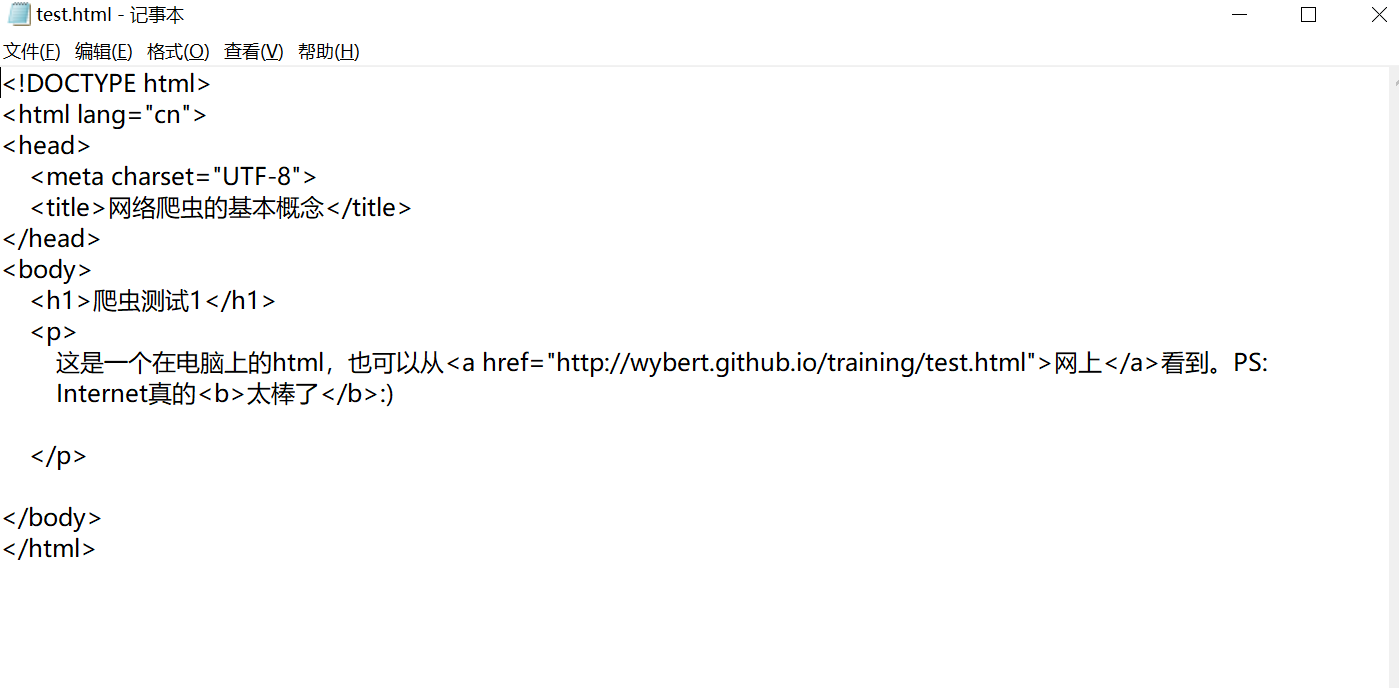

PPT原源码截图：标签决定结构，浏览器会解释并显示它们。图中旧地址是历史版本，当前在线例子见上方链接。

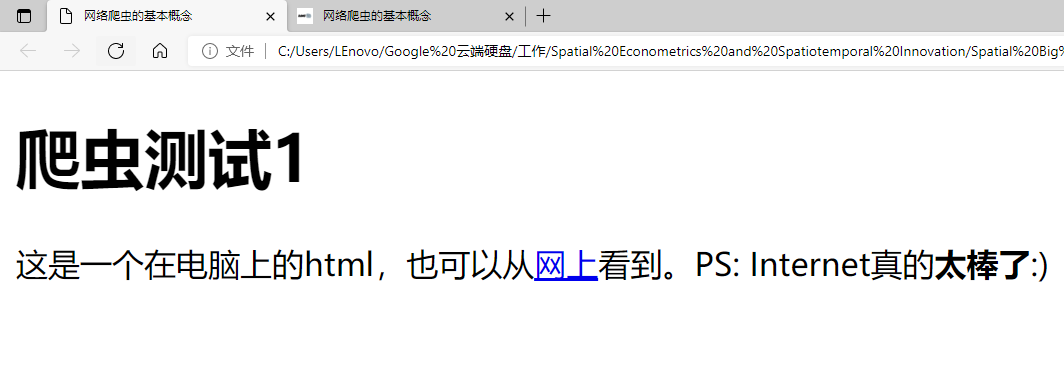

PPT原浏览器截图：同一HTML对应标题、段落、链接和加粗文字。

In [ ]:
local_markup = HTML_FILE.read_text(encoding='utf-8')
local_soup = BeautifulSoup(local_markup, 'html.parser')
print('页面大标题：', local_soup.h1.get_text(strip=True))
print('链接文字：', local_soup.a.get_text(strip=True))
print('链接目标：', local_soup.a.get('href'))
display(HTML(local_markup))

### 短练习 1：两行代码提取标题与链接

从 `local_soup` 中取出 `h1` 的文字和 `a` 的 `href`，分别保存为 `heading_student`、`href_student`。
可用两行赋值完成；随后显示结果。

<details><summary>展开参考答案</summary><p>一个是元素内部的文字，一个是链接属性；不要把链接文字“网上”当成URL。</p><pre><code class="language-python">heading_student = local_soup.h1.get_text(strip=True)
href_student = local_soup.a.get(&#x27;href&#x27;)
print(heading_student, href_student)</code></pre></details>

<a id="url"></a>
## 2．URL：知道向哪个账号的哪一页发请求

原项目拼接 `https://weibo.cn/{用户ID}/profile?...&page=1`。
教学版使用Requests组织查询参数，避免漏掉问号、连接符或页码。
`prepare()`只构造地址，**不会发送请求**。

目标用户与登录用户是两个概念：Cookie来自你自己登录的账号；目标ID是你准备访问的公开用户。
昵称不一定唯一，自定义短地址也不一定是数字ID。先在浏览器打开目标的公开用户资料，
从数字形式的用户地址（如`weibo.cn/u/数字ID`或`weibo.cn/数字ID`）核对。
找不到数字ID时先完成URL练习，不把未知昵称猜成数字ID。

| URL部分 | 含义 |
|---|---|
| `https://weibo.cn` | 登录并访问的站点 |
| `/{user_id}/profile` | 目标用户页面 |
| `hasori=1` | 沿用原项目的原创筛选参数 |
| `page=1`、`page=2` | 本课只请求的两页 |

这些参数来自历史代码，是否仍按预期筛选要对照真实响应。
发送原创筛选参数不自动证明返回的每条记录都是原创。

In [ ]:
def build_profile_url_ref(user_id, page=1):
    user_id = str(user_id).strip()
    if not re.fullmatch(r'[0-9]{1,20}', user_id):
        raise ValueError('请填写目标公开用户的数字ID')
    if type(page) is not int or page not in (1, 2):
        raise ValueError('本课只访问第1、2页')
    request = requests.Request('GET', f'https://weibo.cn/{user_id}/profile',
                               params={'hasori': 1, 'page': page})
    return request.prepare().url

print(build_profile_url_ref(EXAMPLE_USER_ID, 1))
print('查询参数：', parse_qs(urlparse(build_profile_url_ref(EXAMPLE_USER_ID, 1)).query))

### 短练习 2：生成前两页地址

用 `build_profile_url_ref` 和 `EXAMPLE_USER_ID` 生成第1、2页地址，放进 `urls_student` 列表。
可以一行列表推导式完成，再打印列表。此练习不联网。

<details><summary>展开参考答案</summary><p>只改变page参数；账号ID和筛选条件保持一致。</p><pre><code class="language-python">urls_student = [build_profile_url_ref(EXAMPLE_USER_ID, page) for page in (1, 2)]
print(urls_student)</code></pre></details>

<a id="cookie"></a>
## 3．登录weibo.cn，找到并保存自己的Cookie

### 3.1 为什么先登录？

浏览器登录后会保存当前会话的Cookie，并在请求时发送给网站。
Python不会自动继承浏览器登录状态；本课让学生从自己的请求中复制Cookie，运行时加载。
**登录入口是 [https://weibo.cn/](https://weibo.cn/)，先完成登录，再查看请求。**
使用本人账号和当前会话；别人电脑的Cookie不能当成自己的配置。

### 3.2 Chrome／Edge的具体操作

1. 打开 `https://weibo.cn/`，用自己的账号完成登录。在浏览器确认能看到目标公开用户页面。
2. 打开开发者工具：Windows通常按 `F12` 或 `Ctrl+Shift+I`；macOS按 `Cmd+Option+I`。
3. 点 **Network（网络）**，保持记录开启；然后刷新当前微博页面。
4. 点 **Doc／Document** 筛选，选择当前微博用户页面的主文档请求，避免选图片、JS或CSS。
5. 在 **Headers（标头）→ General（常规）** 核对 **Request URL**，域名应为 `weibo.cn`。
   如果选到登录跳转页，先回浏览器完成登录，再刷新目标页面。
6. 展开 **Request Headers（请求标头）**，找到 **Cookie**，复制它的完整值。
   复制内容通常是多项 `名称=值`，项之间用分号分隔；只复制值，不包含开头的 `Cookie:`。
7. 如果显示折叠或截断，展开标头或点击 **view source／查看源代码** 再复制。
   也可查看该请求的 **Cookies** 标签页中的 **Request Cookies**，将各项按 `名称=值; ...` 组织。
8. **Response Headers中的Set-Cookie是服务器发回的设置指令，不能直接替代本例需要的请求Cookie。**
9. 回到Notebook，按下一节保存到自己的本地配置；不要把Cookie粘在代码格或截图中。

`weibo.cn`与`weibo.com`的域名不同，不能假定会话值通用。
Cookie缺失时，先确认选中的是登录后的主文档请求，而不是其他域名的资源。
会话过期时重新登录并获取当前请求中的值；遇到验证码或限制就停止操作。

[Chrome Network说明](https://developer.chrome.com/docs/devtools/network/reference)

### 3.3 本地配置怎么填写？

公开仓库中只有空白模板 `config/weibo_cookie.example.json`。
每位学生生成自己的 `config/weibo_cookie.local.json`，包含两个字段：

```json
{"cookie": "", "user_id": ""}
```

`cookie`填自己的会话；`user_id`填要采集的公开账号数字ID。
下面的函数用隐藏输入取得Cookie，保存时设为本机用户可读写；文件已列入gitignore。
教师的私有配置不随公开仓库发布。只打印“配置存在”等状态，不显示配置内容。

**学生操作：** 开场将 `WRITE_MY_CONFIG=True`，运行开场与下一格，按提示输入。
保存后将开关改回False；也可以复制模板并在本机编辑，注意不要误提交本地配置。

In [ ]:
def save_private_config_ref(cookie, user_id=''):
    cookie = cookie.strip()
    if not cookie or '\n' in cookie or '\r' in cookie:
        raise ValueError('请输入一行完整的请求Cookie值')
    CONFIG_FILE.parent.mkdir(parents=True, exist_ok=True)
    if CONFIG_FILE.exists():
        os.chmod(CONFIG_FILE, 0o600)
    fd = os.open(CONFIG_FILE, os.O_WRONLY | os.O_CREAT | os.O_TRUNC, 0o600)
    with os.fdopen(fd, 'w', encoding='utf-8') as stream:
        json.dump({'cookie': cookie, 'user_id': str(user_id).strip()}, stream, ensure_ascii=False, indent=2)
    os.chmod(CONFIG_FILE, 0o600)

def load_private_config_ref():
    if not CONFIG_FILE.is_file():
        raise FileNotFoundError('请先按第3部分生成自己的本地Cookie配置')
    settings = json.loads(CONFIG_FILE.read_text(encoding='utf-8'))
    cookie = settings.get('cookie', '').strip()
    if not cookie or '\n' in cookie or '\r' in cookie:
        raise ValueError('本地配置中的Cookie为空或包含换行')
    return {'cookie': cookie, 'user_id': str(settings.get('user_id', '')).strip()}

if WRITE_MY_CONFIG:
    private_cookie = getpass('粘贴自己的Cookie值（隐藏输入）：')
    private_user_id = input('要采集的公开用户数字ID：').strip()
    try:
        save_private_config_ref(private_cookie, private_user_id)
        print('本地配置已保存；未显示Cookie。')
    finally:
        private_cookie = None
else:
    print('本次未改写配置；文件存在：', CONFIG_FILE.is_file())

<a id="request"></a>
## 4．发送请求：HTTP成功和拿到微博是两回事

原项目的 `Parseurl(url)` 用`urllib2`下载页面。
这里拆成“读配置 → 组织请求头 → GET → 检查 → 返回正文与元数据”。
这个函数先定义，稍后在第6部分统一调用，避免示范同一页时重复联网。

| 语句 | 用途 |
|---|---|
| `headers['Cookie'] = cookie` | 携带自己的登录会话 |
| `timeout=15` | 网络长时间无响应时抛出异常 |
| `allow_redirects=False` | 先识别登录等跳转，不自动跟随 |
| `raise_for_status()` | 将4xx／5xx等HTTP失败转成异常 |
| `response.encoding` | 决定字节怎样解码成中文文本 |
| `BeautifulSoup(...)` | 把正文变成可选择的标签树 |

200只说明HTTP返回成功，正文可能仍是登录页。需要同时检查HTML内容类型、帖子容器与关键字段。
`apparent_encoding`是编码推测，中文乱码时要对照页面的`charset`。
下载得到的HTML和解析后的帖子是两个阶段，报错时先定位在哪一阶段。

In [ ]:
def read_page_ref(url, *, cookie):
    parsed = urlparse(url)
    if parsed.scheme != 'https' or parsed.hostname != 'weibo.cn' or parsed.username or parsed.password:
        raise ValueError('本课只向https://weibo.cn发送页面请求')
    query = parse_qs(parsed.query)
    if query.get('page') not in (['1'], ['2']):
        raise ValueError('本课只访问第1、2页')
    headers = {'User-Agent': 'Mozilla/5.0', 'Cookie': cookie}
    try:
        with requests.get(url, headers=headers, timeout=15, allow_redirects=False) as response:
            if 300 <= response.status_code < 400:
                raise RuntimeError('发生页面跳转，请在浏览器完成登录并重新核查')
            response.raise_for_status()
            content_type = response.headers.get('Content-Type', '')
            if 'html' not in content_type.lower():
                raise RuntimeError('响应不是HTML，停止解析')
            response.encoding = response.apparent_encoding or response.encoding or 'utf-8'
            markup = response.text
            soup = BeautifulSoup(markup, 'html.parser')
            valid = any(div.get('id') and div.select_one('span.ctt') and div.select_one('span.ct')
                        for div in soup.select('div.c'))
            if not valid:
                raise RuntimeError('未识别到微博结构：请检查登录、访问限制或页面布局')
            metadata = {'url': url, 'status_code': response.status_code,
                        'content_type': content_type, 'encoding': response.encoding,
                        'n_bytes': len(response.content),
                        'fetched_at': datetime.now(timezone.utc).isoformat()}
            return markup, metadata
    finally:
        headers.clear()

<a id="parse"></a>
## 5．解析：一条微博是字典，一页微博是字典列表

原 `parse_one_weibo` 的核心是先定位正文和时间，再遍历链接。
下面保留其字段思路，并补上缺失检查：导航、页脚或布局异常的块不强行生成帖子。

| 历史HTML线索 | 字段 | 为什么这样处理 |
|---|---|---|
| `div.c`的id | `post_id` | 用于记录标识与跨页去重 |
| `span.ctt` | `text` | 取该条记录的文字，不取整个页面 |
| `span.ct` | `time_raw` | 保留相对时间及来源，先不猜绝对日期 |
| 原图链接 | `image_url` | 只记录链接，本课不下载图片 |
| `赞[数字]`等链接文字 | `thumb`、`repost`、`comment` | 提取当次页面的观测值；缺失保持None |

`get_text(' ', strip=True)`将嵌套标签的文字组织成字符串；`find_all('a', href=True)`遍历有链接属性的元素。
正则表达式中的`\d+`表示一个或多个数字。不能识别“万”等格式时保持未知，不填0。
原图链接可能是图片查看页面；正文可能被截断，记录链接不等于已经获取全文。

原代码按位置用`[1:-2]`去掉导航与页脚，我们改为检查id、正文和时间。
选择器属于历史结构，仍需与当前真实页面逐条核对。

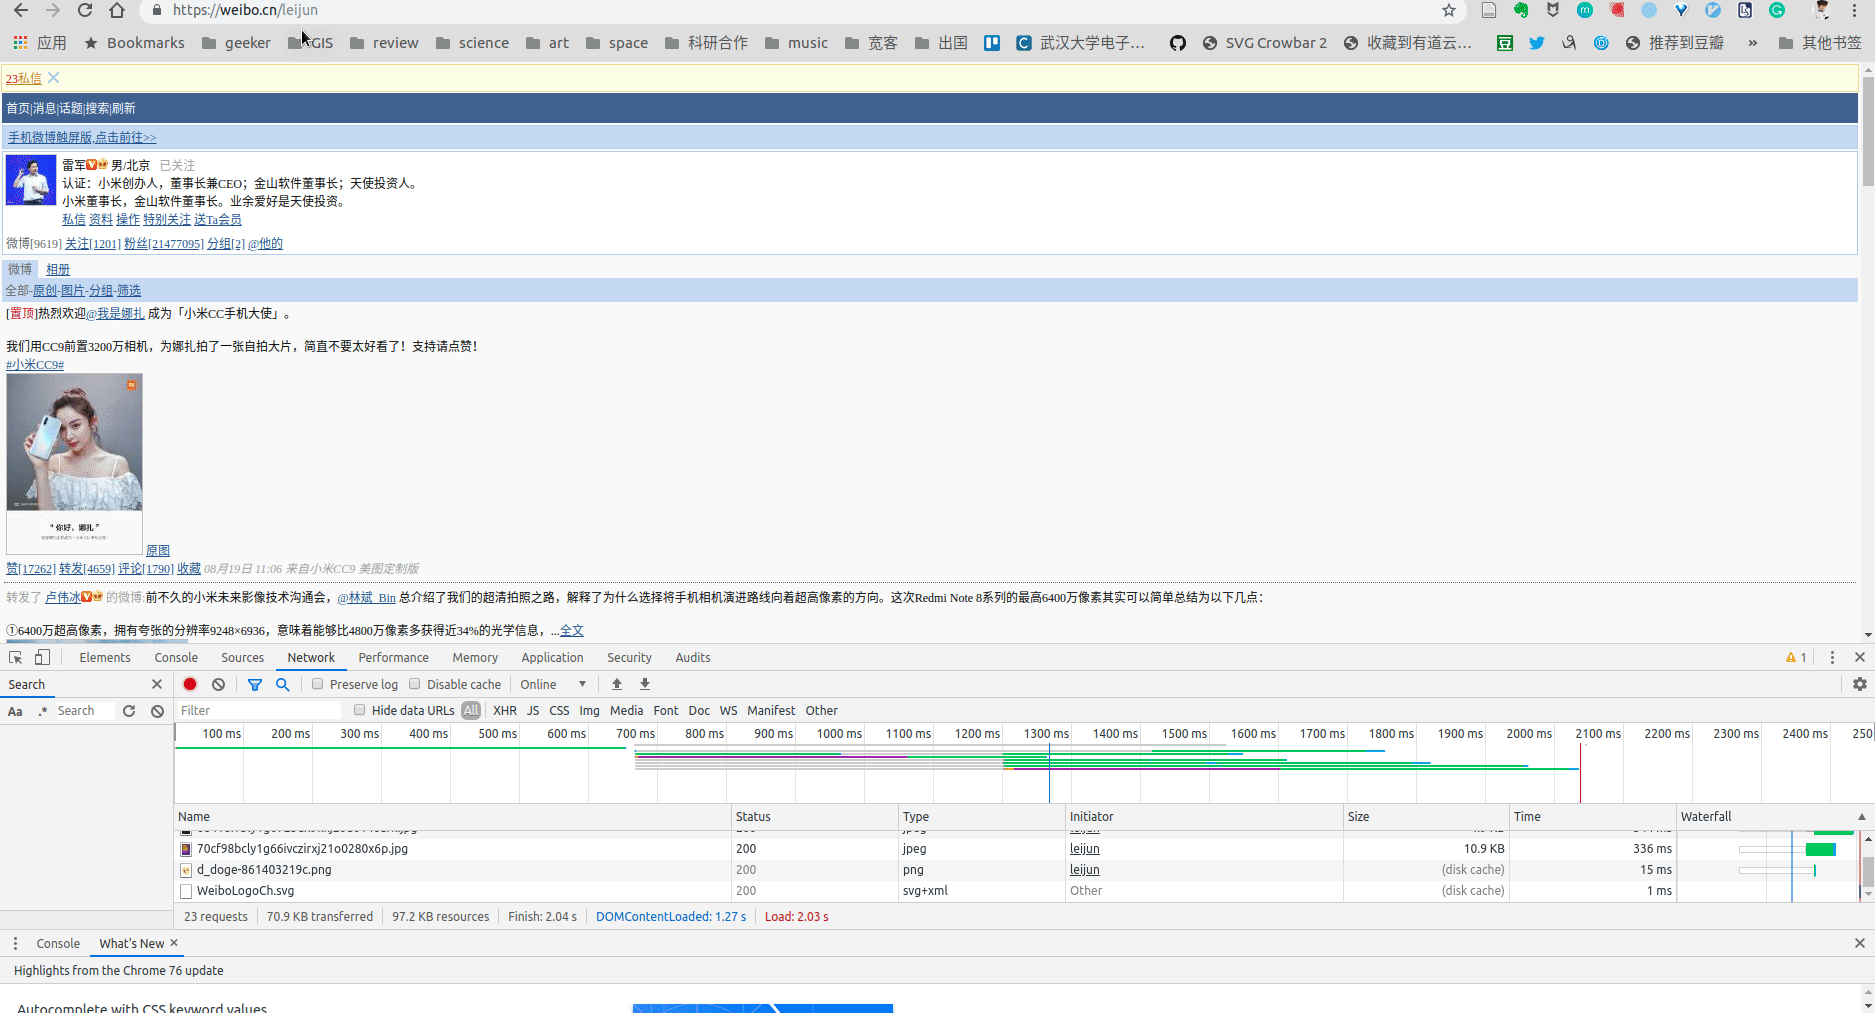

原项目2019操作动图中的雷军公开页面与Network列表。仅帮助认识记录和请求位置；不是本次采集结果，截图不含Cookie值。

In [ ]:
def metric_from_links_ref(links, prefix):
    pattern = re.compile(r'^' + re.escape(prefix) + r'\[(\d+)\]$')
    for link in links:
        match = pattern.fullmatch(link.get_text(strip=True))
        if match:
            return int(match.group(1))
    return None

def parse_one_weibo_ref(div, *, user_id, source_url):
    body, stamp = div.select_one('span.ctt'), div.select_one('span.ct')
    if not div.get('id') or body is None or stamp is None:
        return None
    links = div.find_all('a', href=True)
    image_link = next((a.get('href') for a in links if '原图' in a.get_text()), None)
    return {'post_id': div.get('id'), 'user_id': str(user_id),
            'text': body.get_text(' ', strip=True), 'time_raw': stamp.get_text(' ', strip=True),
            'image_url': urljoin(source_url, image_link) if image_link else None,
            'thumb': metric_from_links_ref(links, '赞'),
            'repost': metric_from_links_ref(links, '转发'),
            'comment': metric_from_links_ref(links, '评论')}

def parse_page_num_ref(soup):
    element = soup.select_one('div.pa input[name="mp"]')
    value = element.get('value', '') if element is not None else ''
    return int(value) if value.isdigit() and int(value) > 0 else None

def parse_page_ref(markup, *, user_id, source_url):
    soup, rows = BeautifulSoup(markup, 'html.parser'), []
    for div in soup.select('div.c'):
        row = parse_one_weibo_ref(div, user_id=user_id, source_url=source_url)
        if row is not None:
            rows.append(row)
    return rows, parse_page_num_ref(soup)

### 为什么函数要分开？

`read_page_ref`返回HTML和请求元数据；`parse_one_weibo_ref`返回一条字典或None；
`parse_page_ref`返回字典列表和识别到的总页数。
这样可以分别核对请求是否成功、每个选择器是否正确、循环是否漏记录。
`append`加入一条字典，`extend`合并一页的字典列表。

`parse_page_num_ref`读取隐藏input的`value`属性；缺分页元素返回None，表示页数未知。
**本课页数只用于观察，即使显示很多页，也不继续请求第3页。**

<a id="collect"></a>
## 6．加载自己的配置，只采目标用户前两页

将开场的`USER_ID`填写为目标数字ID，或者使用配置中的`user_id`；
将`RUN_LIVE=True`，再运行开场和本部分。配置仍从本机读取，不显示Cookie。

流程固定为：**第1页 → 等待30秒 → 第2页 → 合并 → 按post_id去重**。
如果第一页表明账号只有一页，就结束；错误时直接停止，不循环重试。
`source_page`记录来自第几页，`source_url`和`fetched_at`记录采集来源与时刻。
结果不是完整用户历史，也不能从两页估计长期发帖频率。

全部联网请求集中在下一格的一次函数调用中，前面的示范只定义函数。
改参数后再次运行会再次请求页面，先确认是否确实需要。

In [ ]:
RECORD_COLUMNS = ['post_id', 'user_id', 'text', 'time_raw', 'image_url',
                  'thumb', 'repost', 'comment', 'source_page', 'source_url', 'fetched_at']

def collect_first_two_pages_ref(user_id, *, cookie):
    all_rows, metadata_rows = [], []
    for page in (1, 2):  # 固定只有这两个页码，没有动态扩张范围。
        if page == 2:
            time.sleep(30)
        url = build_profile_url_ref(user_id, page)
        markup, meta = read_page_ref(url, cookie=cookie)
        rows, total_pages = parse_page_ref(markup, user_id=user_id, source_url=url)
        if not rows:
            raise RuntimeError('真实页面没有解析到记录，停止并核查')
        for row in rows:
            row.update(source_page=page, source_url=url, fetched_at=meta['fetched_at'])
        all_rows.extend(rows)
        metadata_rows.append({**meta, 'page': page, 'parsed_rows': len(rows), 'total_pages': total_pages})
        if total_pages is not None and page >= total_pages:
            break
    frame = pd.DataFrame(all_rows, columns=RECORD_COLUMNS)
    return frame.drop_duplicates('post_id').reset_index(drop=True), pd.DataFrame(metadata_rows)

live_table = pd.DataFrame(columns=RECORD_COLUMNS)
request_log = pd.DataFrame()
if RUN_LIVE:
    private_settings = {}
    try:
        private_settings = load_private_config_ref()
        target_user = USER_ID.strip() or private_settings['user_id']
        live_table, request_log = collect_first_two_pages_ref(target_user, cookie=private_settings['cookie'])
        print('实际请求页码：', request_log['page'].tolist())
        print('去重后记录数：', len(live_table))
        display(request_log[['page', 'status_code', 'parsed_rows', 'total_pages']])
    except (requests.RequestException, RuntimeError, ValueError, FileNotFoundError) as exc:
        print('采集停止：', type(exc).__name__, str(exc))
    finally:
        private_settings.clear()
else:
    print('采集开关关闭；未发微博请求。配置完成后可采前两页。')

<a id="save"></a>
## 7．检查与保存：先核对三条，再留本机CSV

打开真实页面，人工对照三条记录的正文、时间、互动字段与来源页码。
当前缺真实结果时，下面不生成替代帖子，也不把空表说成账号没有发帖。
第三道练习只读已经采到的前两页结果，不再发送请求。

### 短练习 3：用少量代码检查前两页结果

在存在真实 `live_table` 时，显示前三行的 `text`、`time_raw`、`source_page`，再打印总记录数。
用两行主体代码即可。若没有采集结果，打印“尚未采集”，不编造数据。

<details><summary>展开参考答案</summary><p>先检查输出字段与页面是否一致；练习读取已有结果，不触发新的抓取。</p><pre><code class="language-python">if not live_table.empty:
    display(live_table[[&#x27;text&#x27;, &#x27;time_raw&#x27;, &#x27;source_page&#x27;]].head(3))
    print(&#x27;前两页去重后记录数：&#x27;, len(live_table))
else:
    print(&#x27;尚未采集；请先登录、配置并运行前两页采集。&#x27;)</code></pre></details>

### 保存字段、编码与来源

原项目按页追加CSV。本课先合并、去重，再保存一次快照，减少重复表头和重复记录。
按帖子id去重，不按正文：不同帖子可能正文相同。
互动量缺失保持空值，`utf-8-sig`方便常见表格软件识别中文，`index=False`不另存行索引。

开场`SAVE_CSV=True`后，下一格仅在有真实结果时写入`output/crawler/`。
同时保存请求元数据：页面、状态和采集时刻；其中不包含Cookie或请求头。
本机采集文件和Notebook运行输出不提交公开仓库。保存时刻与帖子发布时间也要区分。

In [ ]:
if SAVE_CSV and not live_table.empty:
    OUT.mkdir(parents=True, exist_ok=True)
    saved_at = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    destination = OUT / f'weibo_first_two_pages_{saved_at}.csv'
    clean = live_table.copy()
    for field in ['thumb', 'repost', 'comment']:
        clean[field] = pd.to_numeric(clean[field], errors='coerce').astype('Int64')
    clean.to_csv(destination, index=False, encoding='utf-8-sig')
    log = {'saved_at_utc': saved_at, 'n_rows': len(clean),
           'requests': request_log.to_dict('records'),
           'csv_sha256': hashlib.sha256(destination.read_bytes()).hexdigest()}
    destination.with_suffix('.json').write_text(json.dumps(log, ensure_ascii=False, indent=2), encoding='utf-8')
    print('已保存本机结果：', destination.name)
else:
    print('未保存采集结果。')

## 函数与原项目的对应关系

| 原项目 | 本教学版 | 本课讲解重点 |
|---|---|---|
| `HEADERS` | 本地配置 + 请求头字典 | 学生自己的登录会话 |
| `Parseurl` | `read_page_ref` | 请求与响应检查 |
| `parse_one_weibo` | `parse_one_weibo_ref` | 一条字典、缺失字段 |
| `parse_page_num` | `parse_page_num_ref` | 读取隐藏input属性 |
| `get_page_num` | 页解析结果中的总页数 | 观察，不扩张采集范围 |
| 页面循环 | `collect_first_two_pages_ref` | 固定前两页、extend、去重 |
| `save_weibosData` | 最后一格的快照保存 | 编码、来源、本机输出 |

原项目还有按月组织日期、拆分大区间和断点恢复的代码，适合完整采集任务的设计讨论。
本课只介绍这些经验，不运行日期分段或第3页以后的采集。

**课上反馈：** 说清自己的URL、Cookie获取位置、一个选择器和实际完成阶段。
默认离线运行只能验证本地HTML与代码组织；真实字段必须用自己的页面核对。

- [原项目](https://github.com/wybert/weiboUserCrawler)
- [Requests入门](https://requests.readthedocs.io/en/latest/user/quickstart/)
- [Beautiful Soup文档](https://www.crummy.com/software/BeautifulSoup/bs4/doc/)
- [Chrome Network参考](https://developer.chrome.com/docs/devtools/network/reference)